# Пари 33–34 · маршрут на 90 + 90 хвилин з повторенням пар 31–32

За два блоки по 90 хвилин ви згадаєте, як на парах 31–32 стиснули 13 ознак вина до двох осей, а потім навчитеся знаходити групи там, де ніхто не дав кольорів: поділите клієнтів ClientScope на сегменти двома алгоритмами — K-Means і DBSCAN.

| Блок | Час | Що робимо |
|---|---|---|
| **1** | 0:00–0:30 | Повторення: пара 31 → 32 і місток до кластеризації |
| | 0:30–1:30 | Пара 33 · кластеризація K-Means (практичне 7.2, завдання 1–2) |
| **2** | 0:00–1:30 | Пара 34 · DBSCAN і сегментація клієнтів (практичне 7.2, завдання 3–4) |

Час у кожному блоці йде від його початку. Усі команди запускайте **з кореня репозиторію** — з тієї папки, де лежить цей файл.

По дорозі є девʼять **міні-завдань** на 2–3 хвилини: одна змінена команда або один-два рядки коду. Їх робите ви самі, одразу після прикладу.

Маршрут є у двох формах: цей текст і ноутбук [PythonAI_Author_Lesson33_Lesson34.ipynb](PythonAI_Author_Lesson33_Lesson34.ipynb), де під кожною командою вже є її вивід і всі рисунки. Ноутбук відкривайте з кореня репозиторію, ядро — `.venv`. Комірки міні-завдань у ньому порожні: їх запускаєте ви.

Докладний варіант лише пар 33–34 на 180 хвилин: [Lesson33_34_plan_180.md](../PythonAI_Author_Lesson33_Lesson34/Lesson33_34_plan_180.md). Попередній маршрут, пари 31–32: [PythonAI_Author_Lesson31_Lesson32.md](PythonAI_Author_Lesson31_Lesson32.md).

<a id="step-0"></a>
## Підготовка

Один спільний venv у корені (Python 3.10–3.14):

```text
python -m venv .venv
.venv\Scripts\activate          (Windows)
source .venv/bin/activate        (macOS / Linux)
python -m pip install -U pip
python -m pip install -r requirements.txt
```

Перевірка — дві команди:

In [1]:
import os
import subprocess
import sys
from pathlib import Path

from IPython.display import Image, display

ROOT = Path.cwd()
assert (ROOT / "requirements.txt").exists() and (ROOT / "PythonAI_Author_Lesson31_Lesson32").is_dir(),     "Відкрийте ноутбук із кореня репозиторію python61_ai"


def run(script, *args):
    """Запустити скрипт пари тим самим Python, що й ноутбук, і надрукувати його вивід."""
    env = dict(os.environ, PYTHONIOENCODING="utf-8")
    done = subprocess.run(
        [sys.executable, script, *args], cwd=ROOT, env=env,
        capture_output=True, text=True, encoding="utf-8", errors="replace",
    )
    print(done.stdout + done.stderr)


def show(path):
    display(Image(filename=str(ROOT / path)))

In [2]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_05_wine_map.py")
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_05_client_segments.py")

Карта: 178 вин, 13 ознак → 2 осі, на них 55.4% розкиду таблиці (PC1 36.2%, PC2 19.2%)

Вино №0, справжній сорт 0
   на карті: PC1 = +3.32, PC2 = +1.44
   сусіди:   №10 (сорт 0), №52 (сорт 0), №58 (сорт 0), №13 (сорт 0), №42 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Вино №70, справжній сорт 1
   на карті: PC1 = -1.57, PC2 = -0.88
   сусіди:   №61 (сорт 1), №112 (сорт 1), №127 (сорт 1), №129 (сорт 1), №122 (сорт 1)
   сусіди підказують сорт 1 (5 з 5)

Вино №150, справжній сорт 2
   на карті: PC1 = -2.32, PC2 = +2.36
   сусіди:   №176 (сорт 2), №172 (сорт 2), №169 (сорт 2), №166 (сорт 2), №168 (сорт 2)
   сусіди підказують сорт 2 (5 з 5)

Нове вино: середнє, але alcohol=14.5, proline=1500, flavanoids=3.5
   на карті: PC1 = +1.58, PC2 = +1.77
   сусіди:   №17 (сорт 0), №33 (сорт 0), №45 (сорт 0), №7 (сорт 0), №53 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Рисунок: results\wine_map.png

Карта не знає сортів: кольори додано вже після PCA. Нове вино не змінює осей —
для нього викликаєм

Клієнтів: 500; ознаки spend (грн/міс) і visits (разів/міс) масштабовано StandardScaler

--- K-Means, k = 4
   clients   spend  visits
0      125  1972.2    11.9
1      125   631.8    17.5
2      125   799.9     3.1
3      125  1239.8    19.1

--- DBSCAN, eps = 0.15 (у масштабованих одиницях)
     clients   spend  visits
шум        8  1403.4    11.9
0        124   633.1    17.5
1        122  1972.7    11.9
2        123  1237.3    19.1
3        123   795.6     3.1

Рисунок: results\client_segments.png
Номери сегментів самі нічого не означають. Зміст дає таблиця профілю: хто платить більше, хто ходить частіше.



- [ ] перша друкує `на них 55.4% розкиду таблиці`;
- [ ] друга друкує профілі сегментів K-Means і DBSCAN.

Інтернет і GPU не потрібні. Графіки скрипти зберігають у папку `results/` своєї пари, вікна matplotlib не відкриваються.

---

# Блок 1 · 90 хвилин

<a id="step-1"></a>
## Крок 1 · 0:00–0:12 · Повторення пари 31: карта вин і SVD

In [3]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_05_wine_map.py")

Карта: 178 вин, 13 ознак → 2 осі, на них 55.4% розкиду таблиці (PC1 36.2%, PC2 19.2%)

Вино №0, справжній сорт 0
   на карті: PC1 = +3.32, PC2 = +1.44
   сусіди:   №10 (сорт 0), №52 (сорт 0), №58 (сорт 0), №13 (сорт 0), №42 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Вино №70, справжній сорт 1
   на карті: PC1 = -1.57, PC2 = -0.88
   сусіди:   №61 (сорт 1), №112 (сорт 1), №127 (сорт 1), №129 (сорт 1), №122 (сорт 1)
   сусіди підказують сорт 1 (5 з 5)

Вино №150, справжній сорт 2
   на карті: PC1 = -2.32, PC2 = +2.36
   сусіди:   №176 (сорт 2), №172 (сорт 2), №169 (сорт 2), №166 (сорт 2), №168 (сорт 2)
   сусіди підказують сорт 2 (5 з 5)

Нове вино: середнє, але alcohol=14.5, proline=1500, flavanoids=3.5
   на карті: PC1 = +1.58, PC2 = +1.77
   сусіди:   №17 (сорт 0), №33 (сорт 0), №45 (сорт 0), №7 (сорт 0), №53 (сорт 0)
   сусіди підказують сорт 0 (5 з 5)

Рисунок: results\wine_map.png

Карта не знає сортів: кольори додано вже після PCA. Нове вино не змінює осей —
для нього викликаєм

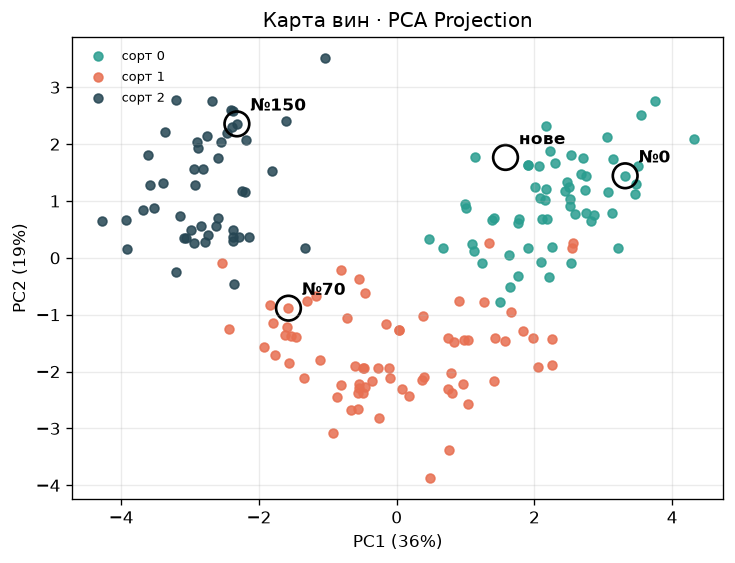

In [4]:
show("../PythonAI_Author_Lesson31_Lesson32/results/wine_map.png")

**Що побачите.** 178 вин, 13 ознак → 2 осі, на них 55.4% розкиду таблиці. У вин №0, №70 і №150 усі пʼять сусідів на карті — того самого сорту.

In [5]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson31_03_svd_projection.py")

1) TruncatedSVD(n_components=2): (178, 13) → (178, 2)
   перші 3 вина в нових координатах:
[[ 3.32  1.44]
 [ 2.21 -0.33]
 [ 2.52  1.03]]
   explained_variance_ratio_ = [0.362 0.192], разом 55.4%
   графік: results\svd_projection.png

2) Той самий SVD без scaler
   кореляція SVD-1 з однією ознакою proline: 1.000
   перша вісь майже дорівнює proline: найбільші числа забрали всю увагу
   графік: results\svd_scaled_vs_raw.png

3) Наскільки добре карта розділяє сорти (kNN на двох координатах, 5-fold)
   без scaler:   70.3%
   після scaler: 96.6%
   усі 13 ознак: 95.5%
   SVD сортів не бачив. kNN тут лише лінійка, якою міряємо карту.



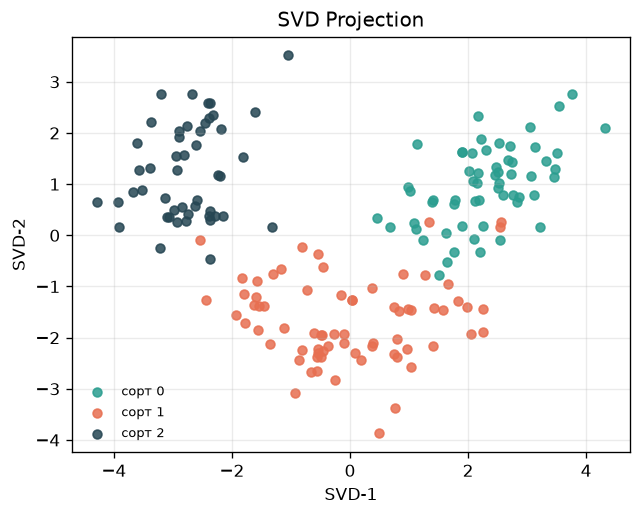

In [6]:
show("../PythonAI_Author_Lesson31_Lesson32/results/svd_projection.png")

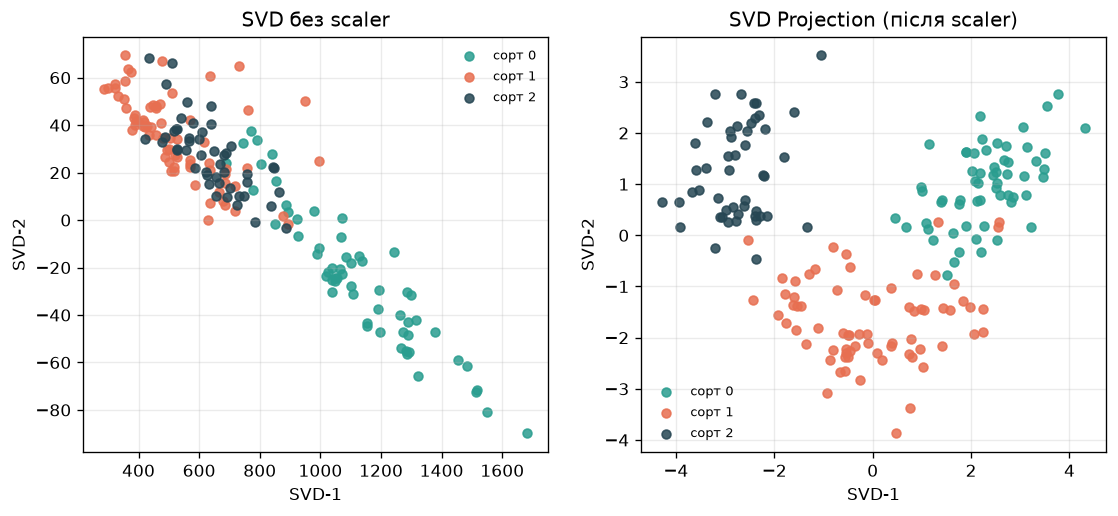

In [7]:
show("../PythonAI_Author_Lesson31_Lesson32/results/svd_scaled_vs_raw.png")

**Що побачите.** `TruncatedSVD(n_components=2)`: `(178, 13) → (178, 2)`. Без scaler перша вісь — це просто `proline` (кореляція 1.000), і сорти на карті розділяються на 70.3%. Зі scaler — на 96.6%.

**Міні-завдання 1 · 2 хв.** Виберіть три свої номери вин від 0 до 177 і перевірте, чи сусіди на карті підказують правильний сорт:

In [ ]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_05_wine_map.py", "10", "100", "170")

Чи знайшлося вино, у якого серед пʼяти сусідів є чужий сорт? Де воно лежить на карті?

**Перевір себе:**
1. Навіщо перед SVD масштабувати ознаки?
2. Карта зберігає 55.4% розкиду. Чому сорти на ній все одно видно добре?

<a id="step-2"></a>
## Крок 2 · 0:12–0:22 · Повторення пари 32: PCA і скільки компонент

In [9]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_02_pca_by_hand.py")

1) PCA руками
   матриця коваріацій (13, 13), власні числа: [4.73 2.51 1.45 0.92] …
   частка кожного: [0.362 0.192 0.111 0.071] …

2) Порівняння з sklearn.decomposition.PCA
   explained_variance_ratio_: [0.362 0.192]
   різниця координат: 3.1e-15

3) Той самий PCA через SVD центрованої таблиці
   s² / (n − 1) = [4.73 2.51 1.45 0.92] — це власні числа з кроку 1
   різниця осей: 1.0e-15

4) TruncatedSVD проти PCA на масштабованому wine
   різниця координат: 9.7e-09
   StandardScaler уже відняв середнє, тому PCA більше нічого центрувати

5) Те саме без scaler (дані не центровані)
   різниця координат SVD і PCA: 759
   косинус між першою віссю SVD і вектором середніх: 0.9998
   перша вісь SVD показує, де лежить хмара відносно нуля, а не як вона розкидана
   SVD-1: від 287 до 1681;  PC1: від -469 до 933

PCA = центрування + SVD. Знак осі довільний: графік може бути дзеркальним, і це не помилка.



**Що побачите.** PCA руками збігається зі `sklearn`. Після scaler `TruncatedSVD` і `PCA` відрізняються лише на `9.7e-09`, без scaler — на 759.

**PCA = центрування + SVD.**

In [10]:
run("PythonAI_Author_Lesson31_Lesson32/Lesson32_04_how_many_components.py")

1) Усі 13 компонент: частка дисперсії і накопичена сума
   PC1   36.2%  разом  36.2%  ██████████████████████
   PC2   19.2%  разом  55.4%  ████████████
   PC3   11.1%  разом  66.5%  ███████
   PC4    7.1%  разом  73.6%  ████
   PC5    6.6%  разом  80.2%  ████
   PC6    4.9%  разом  85.1%  ███
   PC7    4.2%  разом  89.3%  ███
   PC8    2.7%  разом  92.0%  ██
   PC9    2.2%  разом  94.2%  █
   PC10   1.9%  разом  96.2%  █
   PC11   1.7%  разом  97.9%  █
   PC12   1.3%  разом  99.2%  █
   PC13   0.8%  разом 100.0%  

2) Скільки компонент треба, щоб зберегти задану частку
   80% → 5 компонент
   90% → 8 компонент
   95% → 10 компонент
   PCA(n_components=0.90) сам вибрав 8
   графік: results\scree_plot.png

3) PCA як крок перед класифікацією (LogisticRegression, 5-fold)
    k   точність
    1   84.8%
    2   95.5%
    3   96.6%
    5   97.8%
    8   97.8%
   13   98.3%
   без PCA: 98.3%

Scaler і PCA стоять усередині Pipeline: у кожному fold вони навчаються лише на train-частині.
Якщо зро

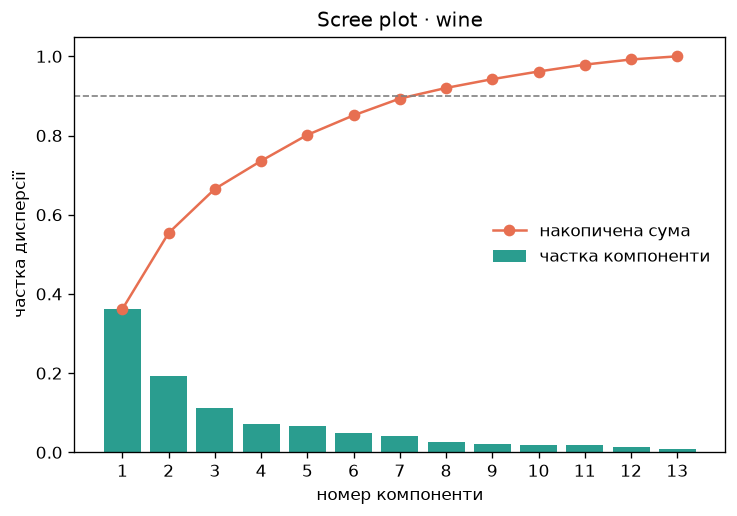

In [11]:
show("../PythonAI_Author_Lesson31_Lesson32/results/scree_plot.png")

**Що побачите.** 80% розкиду зберігають 5 компонент, 90% — 8, 95% — 10. Перед класифікатором PCA стоїть у `Pipeline`, щоб не було leakage.

**Перевір себе:**
3. Чому після `StandardScaler` графіки SVD і PCA однакові?
4. Для нового вина викликають `transform`, а не `fit_transform`. Чому?

<a id="step-3"></a>
## Крок 3 · 0:22–0:30 · Місток: карта вин без кольорів

На парах 31–32 сорти на карті було видно, бо ми самі розфарбували точки за `target`. А якщо кольорів немає?

In [12]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson33_01_wine_without_colors.py")

1) Карта з пари 32: (178, 13) → (178, 2), на двох осях 55.4% розкиду

2) KMeans(n_clusters=3) на тих самих 178 точках, без кольорів
   розміри груп: 0: 64, 1: 49, 2: 65
   центри груп на карті:
[[ 2.27  0.87]
 [-2.74  1.21]
 [-0.16 -1.77]]

3) Лише тепер дивимось на сорти: скільки вин кожного сорту потрапило в кожну групу
кластер   0   1   2
сорт               
0        59   0   0
1         5   1  65
2         0  48   0
   узгодженість із сортами (ARI, 1.0 = ідеально): 0.895

Рисунок: results\wine_without_colors.png

Номери кластерів довільні: кластер 0 не мусить бути сортом 0. Важить лише, хто з ким разом.



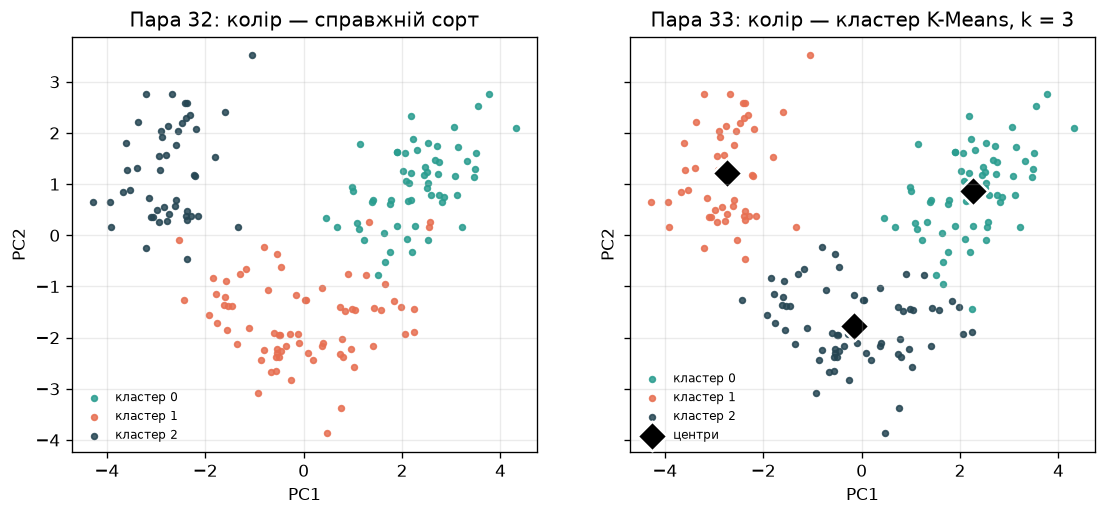

In [13]:
show("../PythonAI_Author_Lesson33_Lesson34/results/wine_without_colors.png")

**Що побачите.** K-Means отримує лише 178 точок на площині і сам ділить їх на 3 групи. Лише потім ми порівнюємо групи із сортами: сорт 0 цілком в одній групі, сорт 2 — в іншій, сорт 1 майже весь у третій. Узгодженість із сортами (ARI) — 0.895. Рисунок `PythonAI_Author_Lesson33_Lesson34/results/wine_without_colors.png`: ліворуч кольори сортів, праворуч — кластерів.

**Зверніть увагу:** номери кластерів довільні. Кластер 0 не мусить бути сортом 0: важить лише, хто з ким разом.

**Міні-завдання 2 · 2 хв.** Попросіть K-Means чотири групи замість трьох:

In [ ]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson33_01_wine_without_colors.py", "4")

Що сталося із сортами? Чи впала узгодженість ARI і чому?

<a id="step-4"></a>
## Крок 4 · 0:30–0:36 · Пара 33 · готова програма: сегменти клієнтів

In [15]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_05_client_segments.py")

Клієнтів: 500; ознаки spend (грн/міс) і visits (разів/міс) масштабовано StandardScaler

--- K-Means, k = 4
   clients   spend  visits
0      125  1972.2    11.9
1      125   631.8    17.5
2      125   799.9     3.1
3      125  1239.8    19.1

--- DBSCAN, eps = 0.15 (у масштабованих одиницях)
     clients   spend  visits
шум        8  1403.4    11.9
0        124   633.1    17.5
1        122  1972.7    11.9
2        123  1237.3    19.1
3        123   795.6     3.1

Рисунок: results\client_segments.png
Номери сегментів самі нічого не означають. Зміст дає таблиця профілю: хто платить більше, хто ходить частіше.



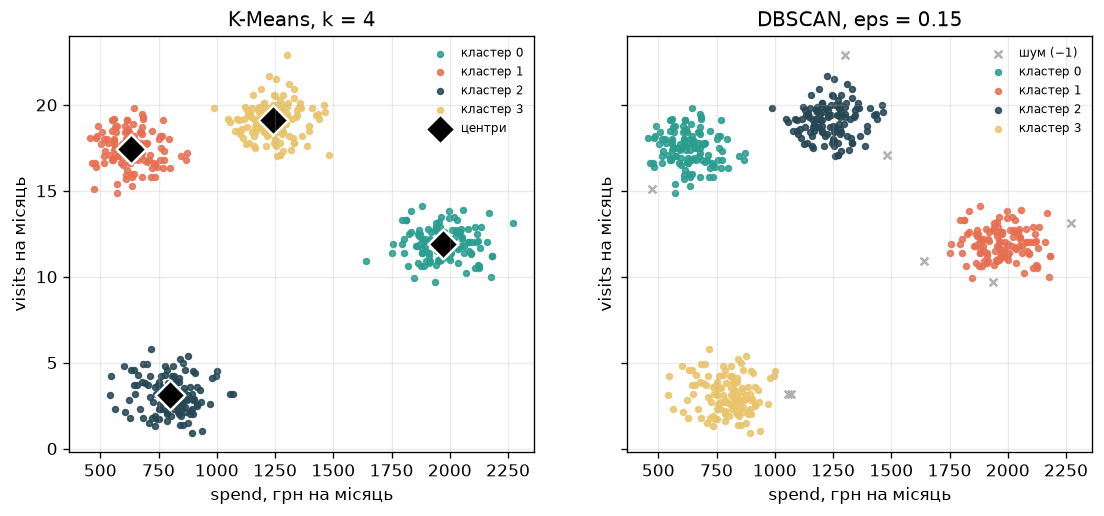

In [16]:
show("../PythonAI_Author_Lesson33_Lesson34/results/client_segments.png")

**Що побачите.** 500 клієнтів ClientScope з двома ознаками: витрати на місяць (`spend`, грн) і візити на місяць (`visits`). K-Means ділить їх на 4 сегменти по 125 клієнтів, у кожного свій профіль: хтось витрачає близько 1970 грн, хтось приходить 19 разів на місяць. DBSCAN знаходить ті самі 4 групи і ще 8 клієнтів, не схожих ні на кого. Рисунок — `PythonAI_Author_Lesson33_Lesson34/results/client_segments.png`.

**Зверніть увагу:** клієнти синтетичні, це ті самі точки, що в практичному 7.2, лише в одиницях бізнесу. Номер сегмента нічого не означає — зміст дає таблиця профілю.

**Міні-завдання 3 · 2 хв.** Додайте нового клієнта і подивіться, куди його віднесуть два алгоритми:

In [ ]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_05_client_segments.py", "--new", "spend=900", "visits=10")

Підберіть такого клієнта, щоб DBSCAN знайшов для нього сегмент. Чим різняться відповіді K-Means і DBSCAN для «дивного» клієнта?

<a id="step-5"></a>
## Крок 5 · 0:36–0:46 · Дані ClientScope (завдання 7.2.1)

У презентації 33: «Старт: сегментація без y», «Приклад · 500 точок у 4 хмарах».

In [18]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson33_02_blobs_raw.py")

1) make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=42)
   DataFrame (500, 2): ознаки x1, x2. Справжні хмари y лежать окремо, у таблицю не йдуть.
     x1    x2
0 -7.69  6.62
1 -9.58 -6.93
2  6.83  1.16

2) Що видно до будь-якої моделі
         x1     x2
mean  -3.39   2.89
std    5.28   6.33
min  -10.42  -9.09
max    7.72  12.87

Рисунок: results\raw_blobs.png
Кольорів немає: групи на око шукаєте ви. Наступний крок — нехай їх шукає K-Means.



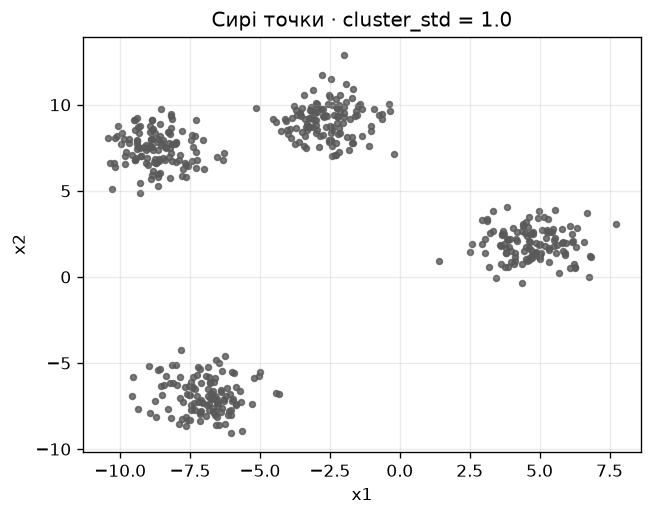

In [19]:
show("../PythonAI_Author_Lesson33_Lesson34/results/raw_blobs.png")

**Що побачите.** `make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=42)` → `DataFrame (500, 2)` з ознаками `x1`, `x2` і сирий scatter без кольорів: `results/raw_blobs.png`.

**Зверніть увагу:** справжні номери хмар лежать окремо, у таблицю не йдуть. Алгоритм бачить лише ознаки.

**Міні-завдання 4 · 2 хв.** Збільште розкид хмар (аналог 1.1):

In [ ]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson33_02_blobs_raw.py", "2.5")

Відкрийте `raw_blobs.png`. Чи ще можна на око сказати, скільки тут груп?

<a id="step-6"></a>
## Крок 6 · 0:46–1:02 · KMeans і cluster_kmeans (завдання 7.2.2)

У презентації 33: «Приклад · перший fit_predict», «Що означають cluster_centers_», «Приклад · центри поверх scatter».

In [21]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson33_03_kmeans_fit.py")

=== KMeans(n_clusters=4, random_state=42)
   розміри кластерів: 0: 125, 1: 125, 2: 125, 3: 125
   cluster_centers_:
[[ 4.72  1.92]
 [-8.68  7.46]
 [-7.   -6.9 ]
 [-2.6   9.09]]
   inertia_ (сума квадратів відстаней до свого центру): 948.9
   збіг зі справжніми хмарами (ARI): 1.000

     x1    x2  cluster_kmeans
0 -7.69  6.62               1
1 -9.58 -6.93               2
2  6.83  1.16               0

Нові клієнти: predict призначає найближчий центр, transform дає відстані до всіх 4
   [[-8.0, 7.0], [0.0, 0.0], [5.0, 2.0]] → кластери [1 0 0]
[[13.7   0.82 13.94  5.79]
 [ 5.1  11.44  9.83  9.46]
 [ 0.29 14.73 14.94 10.4 ]]

Рисунок: results\kmeans_clusters.png
K-Means завжди повертає рівно k груп — навіть якщо справжніх хмар інша кількість.



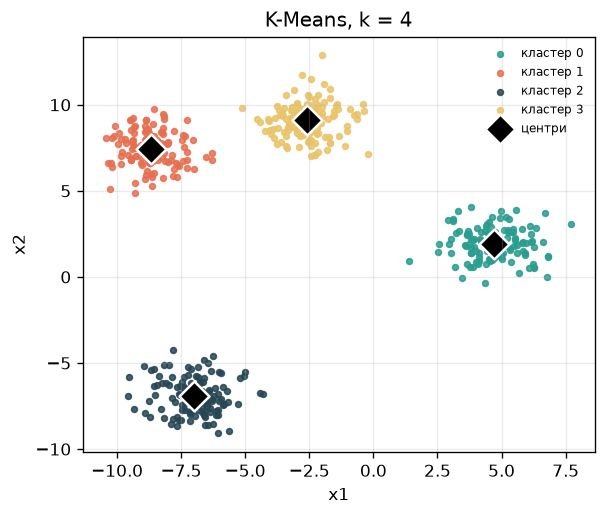

In [22]:
show("../PythonAI_Author_Lesson33_Lesson34/results/kmeans_clusters.png")

**Що побачите.** `KMeans(n_clusters=4, random_state=42)`: 4 кластери по 125 точок, чотири центри, `inertia_ = 948.9`, збіг зі справжніми хмарами (ARI) 1.000. Новим клієнтам `predict` дає найближчий центр, `transform` — відстані до всіх чотирьох. Рисунок — `results/kmeans_clusters.png`.

**Міні-завдання 5 · 2 хв.** Ті самі дані, інше `k` (аналог 2.1):

In [ ]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson33_03_kmeans_fit.py", "2", "6")

Де центри «розривають» справжню хмару? Чому `inertia_` за `k = 6` менша, ніж за `k = 4`, хоча розбиття гірше?

**Часта пастка:** K-Means завжди повертає рівно `k` груп. Він не скаже, що ви неправильно вгадали їх кількість.

**Напишіть самі.** Файл `PythonAI_Author_Lesson33_Lesson34/my_kmeans.py` (готовий лежить у папці пари, якщо не встигаєте набрати):

[125, 125, 125, 125]
0.791


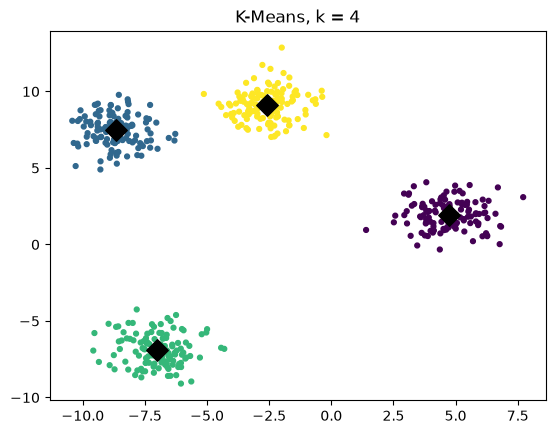

In [24]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

X, _ = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=42)   # номери хмар не беремо
df = pd.DataFrame(X, columns=["x1", "x2"])

kmeans = KMeans(n_clusters=4, random_state=42)
df["cluster_kmeans"] = kmeans.fit_predict(df[["x1", "x2"]])
print(df["cluster_kmeans"].value_counts().sort_index().tolist())          # [125, 125, 125, 125]
print(round(silhouette_score(df[["x1", "x2"]], df["cluster_kmeans"]), 3))  # 0.791
# Міні-завдання 6: порахуйте silhouette для k = 3, 4, 5, 6 у циклі — яке k найкраще?

plt.scatter(df["x1"], df["x2"], c=df["cluster_kmeans"], s=12)
centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], marker="D", s=120, color="black")
plt.title("K-Means, k = 4")
plt.show()

<a id="step-7"></a>
## Крок 7 · 1:02–1:14 · K-Means руками і чому важливий старт

У презентації 33: «За Жероном · як працює алгоритм k-means», «За Жероном · невдалий старт та ініціалізація центроїдів».

In [25]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson33_04_kmeans_by_hand.py")

1) K-Means руками: старт з 5 випадкових точок даних
   ітерація 1: inertia  2079.5, центри зсунулись у середньому на 0.374
   ітерація 2: inertia   714.9, центри зсунулись у середньому на 0.113
   ітерація 3: inertia   653.3, центри зсунулись у середньому на 0.206
   центри перестали рухатись на ітерації 7, inertia 211.6

2) 20 запусків з різним випадковим стартом (init='random', n_init=1)
   inertia: [212, 212, 212, 212, 212, 212, 212, 212, 212, 212, 212, 219, 220, 220, 237, 237, 237, 237, 239, 600]
   n_init=10 лишає найкращий із 10 стартів: 211.6
   k-means++ (розумний старт) з одного запуску: 224.1

Рисунок: results\kmeans_steps.png
Чорні лінії — шлях центрів. K-Means знаходить найближчий локальний мінімум, тому стартів кілька.



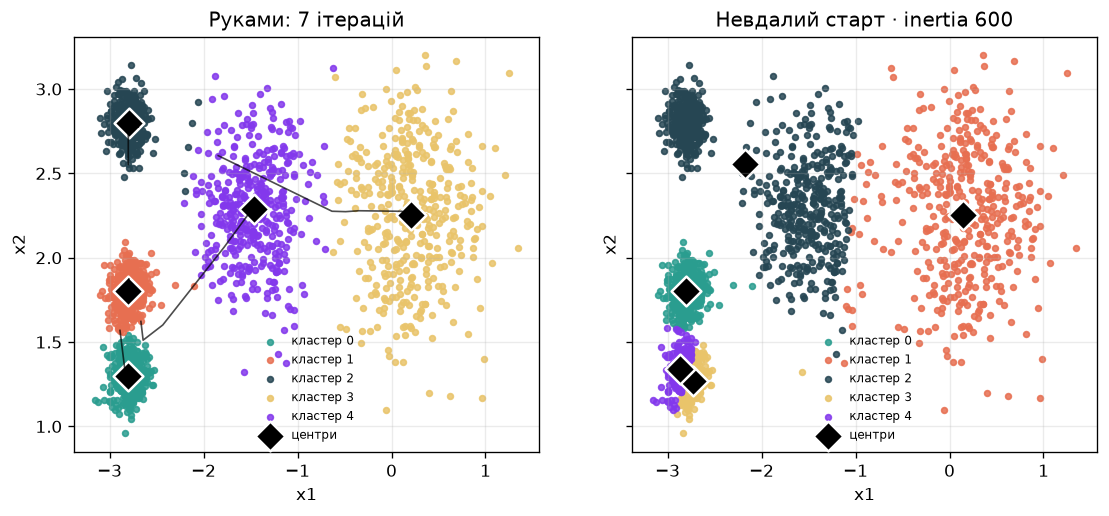

In [26]:
show("../PythonAI_Author_Lesson33_Lesson34/results/kmeans_steps.png")

**Що побачите.**
1. Два кроки в циклі: кожну точку віддаємо найближчому центру, кожен центр переносимо в середнє своїх точок.
2. На пʼяти згустках з книжки центри перестають рухатись на 7-й ітерації, inertia 211.6.
3. З 20 випадкових стартів більшість дає inertia 212, а найгірший — 600: K-Means знаходить найближчий локальний мінімум.
4. `n_init=10` лишає найкращий із 10 стартів (211.6), розумний старт k-means++ з одного запуску дає 224.1.

Рисунок `results/kmeans_steps.png`: ліворуч шлях центрів, праворуч невдалий старт.

**Перевір себе:**
5. Чому K-Means запускають кілька разів з різних стартів?

<a id="step-8"></a>
## Крок 8 · 1:14–1:26 · Скільки кластерів і межі K-Means

У презентації 33: «За Жероном · як знайти оптимальну кількість кластерів», «За Жероном · межі k-means».

In [27]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson33_05_choose_k.py")

1) Пʼять згустків з книжки: inertia завжди падає, silhouette має максимум
   k = 2: inertia  1149.9   silhouette 0.595
   k = 3: inertia   653.2   silhouette 0.572
   k = 4: inertia   261.8   silhouette 0.689
   k = 5: inertia   211.6   silhouette 0.656
   k = 6: inertia   186.7   silhouette 0.590
   k = 7: inertia   146.3   silhouette 0.552
   k = 8: inertia   143.0   silhouette 0.478
   k = 9: inertia   116.1   silhouette 0.486
   найкращий silhouette: k = 4

2) Дані ClientScope (практичне 7.2): найкращий silhouette — k = 4 (0.791)

3) Межі: три еліпси різного розміру
   збіг K-Means зі справжніми групами (ARI): 0.291
   K-Means міряє відстань до центру, тому шукає круглі групи приблизно однакового розміру

Рисунок: results\choose_k.png



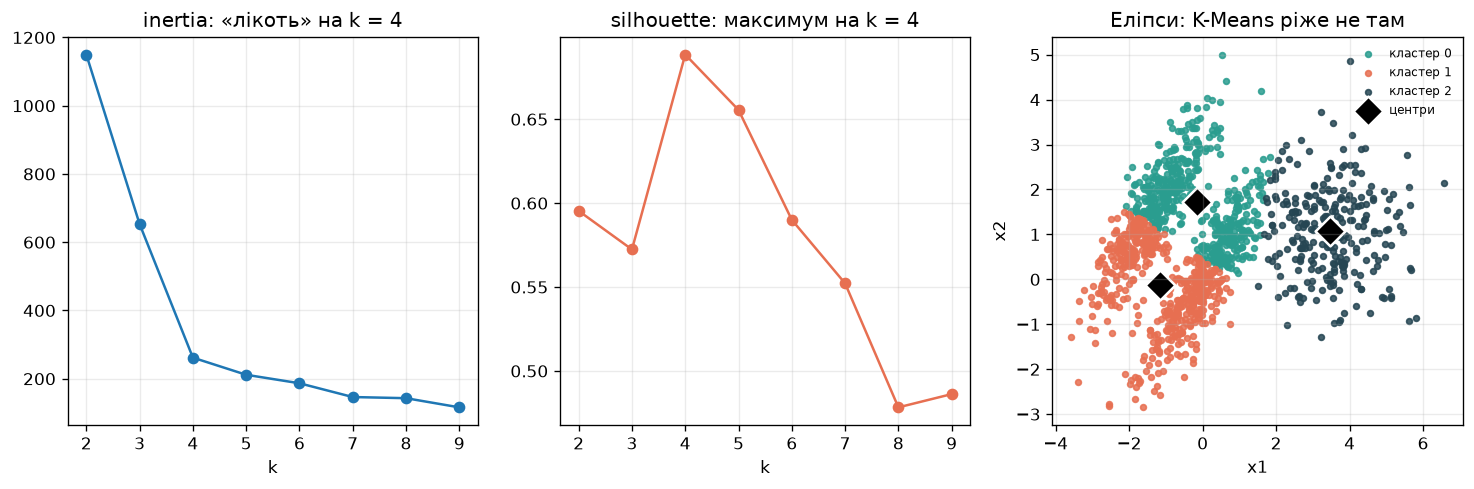

In [28]:
show("../PythonAI_Author_Lesson33_Lesson34/results/choose_k.png")

**Що побачите.** inertia падає з кожним `k`, тому «лікоть» читають на око. Silhouette має максимум: на пʼяти згустках з книжки — за `k = 4` (0.689), хоча згустків пʼять: два з них дуже близько. На даних ClientScope — теж `k = 4` (0.791). На трьох витягнутих еліпсах збіг K-Means зі справжніми групами лише 0.291. Рисунок — `results/choose_k.png`.

**Зверніть увагу:** K-Means міряє відстань до центру, тому знаходить круглі групи приблизно однакового розміру.

**Міні-завдання 6 · 3 хв.** У своєму `my_kmeans.py` допишіть цикл: silhouette для `k` = 3, 4, 5, 6. Яке `k` найкраще для даних ClientScope?

**Перевір себе:**
6. inertia за `k = 9` менша, ніж за `k = 4`. Чому це не означає, що 9 кластерів кращі?

<a id="step-9"></a>
## Крок 9 · 1:26–1:30 · Перевір себе · пара 33

7. Чим кластеризація відрізняється від класифікації?
8. Що повертають `labels_` і `cluster_centers_`?
9. Що означає `inertia_`?
10. Чому K-Means погано ділить витягнуті групи?

---

# Блок 2 · 90 хвилин

<a id="step-10"></a>
## Крок 10 · 0:00–0:05 · Повернення

Шлях пари 33: `make_blobs → DataFrame → KMeans(4) → cluster_kmeans → scatter з центрами`. Кількість кластерів K-Means задаємо самі.

**Перевір себе:**
11. Що станеться, якщо в даних є клієнт, далекий від усіх груп? Куди його віднесе K-Means?

<a id="step-11"></a>
## Крок 11 · 0:05–0:22 · DBSCAN і cluster_dbscan (завдання 7.2.3)

У презентації 34: «Старт: щільність замість K», «Приклад · коло eps навколо точки», «Core, border і noise», «Приклад · скільки шуму при eps=0.8».

DBSCAN не питає кількість кластерів. Він питає, що вважати «густо»: `eps` — радіус сусідства, `min_samples` — скільки точок має бути в цьому радіусі. Точка з густим сусідством — ядрова; поруч з ядровою, але без власного густого сусідства — межова; решта — шум, мітка −1.

In [29]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_01_dbscan.py")

=== DBSCAN(eps=0.8, min_samples=5)
   кластерів: 4, шум (−1): 16 з 500 (3%)
   ядрових точок 466, межових 18, шумових 16
   розміри: шум: 16, 0: 124, 1: 120, 2: 119, 3: 121

     x1    x2  cluster_dbscan
0 -7.69  6.62               0
1 -9.58 -6.93               2
2  6.83  1.16               3

Рисунок: results\dbscan_clusters.png
Мітка −1 — це «шум»: точка не потрапила в жодну густу область. Це не ще один кластер.



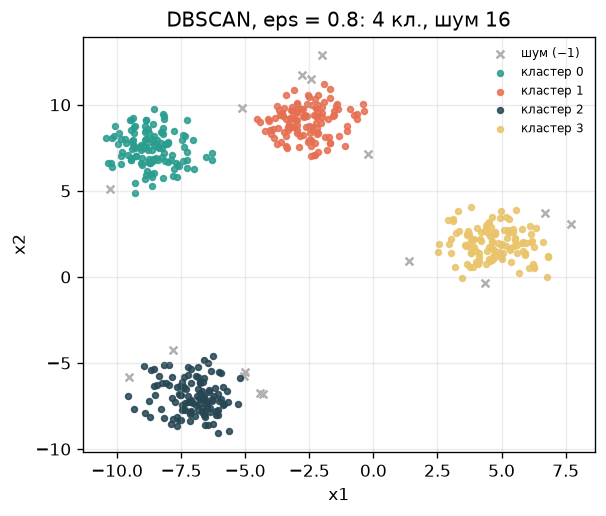

In [30]:
show("../PythonAI_Author_Lesson33_Lesson34/results/dbscan_clusters.png")

**Що побачите.** `DBSCAN(eps=0.8, min_samples=5)`: 4 кластери і 16 точок шуму (3%); 466 ядрових, 18 межових. Стовпець `cluster_dbscan` і рисунок `results/dbscan_clusters.png`.

**Часта пастка:** мітка −1 — не пʼятий кластер, а точки, що не належать жодній густій області.

**Міні-завдання 7 · 2 хв.** Ті самі дані, інший eps (аналог 3.1):

In [ ]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_01_dbscan.py", "0.3", "2.0")

Як змінилися кількість кластерів і частка шуму? Який eps «розсипав» хмари?

<a id="step-12"></a>
## Крок 12 · 0:22–0:35 · Як вибрати eps

У презентації 34: «Як рухається eps», «Приклад · eps замалий, eps завеликий».

In [32]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_02_choose_eps.py")

1) Відстань до 5-го сусіда, відсортована
    50-й перцентиль: 0.35
    90-й перцентиль: 0.72
    95-й перцентиль: 0.87
    99-й перцентиль: 1.33
   100-й перцентиль: 1.98

2) eps навколо злому графіка
   eps = 0.3 : кластерів 21, шум 237
   eps = 0.5 : кластерів 6, шум  67
   eps = 0.8 : кластерів 4, шум  16
   eps = 1.2 : кластерів 4, шум   3
   eps = 2.0 : кластерів 4, шум   0
   eps = 4.0 : кластерів 3, шум   0

3) Масштаб: ознаку x2 записали в інших одиницях (× 100)
   той самий eps = 0.8: кластерів 0, шум 500 з 500
   DBSCAN міряє відстані, тому ознаки в різних одиницях масштабують перед ним — як перед PCA на парі 31

Рисунок: results\k_distance.png



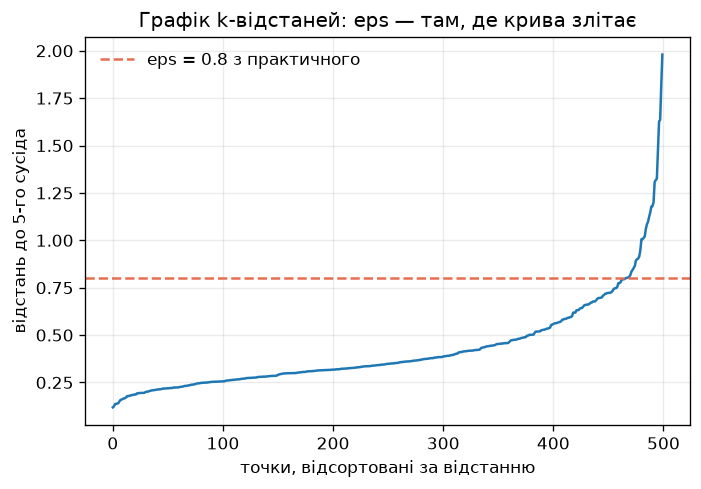

In [33]:
show("../PythonAI_Author_Lesson33_Lesson34/results/k_distance.png")

**Що побачите.** Для кожної точки — відстань до 5-го сусіда, відсортована. Половина точок має сусіда ближче 0.35, 95% — ближче 0.87, далі крива злітає: це шум. Таблиця eps: 0.3 → 21 кластер, 0.8 → 4 кластери і 16 точок шуму, 1.2 → 4 і 3. Якщо ознаку `x2` записати в інших одиницях (× 100), той самий `eps = 0.8` дає 500 точок шуму з 500. Рисунок — `results/k_distance.png`.

**Зверніть увагу:** DBSCAN міряє відстані, тому ознаки в різних одиницях масштабують перед ним — так само, як перед PCA на парі 31.

**Міні-завдання 8 · 2 хв.** Підберіть eps, за якого DBSCAN знаходить 4 кластери, а шуму менше 1% (менше 5 точок). Змінюйте число в команді:

In [ ]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_01_dbscan.py", "1.0")

<a id="step-13"></a>
## Крок 13 · 0:35–0:48 · Півмісяці: де K-Means ламається

У презентації 34: «За Жероном · DBSCAN: кластери як густі області», «За Жероном · нові приклади: чому немає predict()», «За Жероном · k-means і DBSCAN на тих самих даних».

In [35]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_03_moons.py")

1) Той самий DBSCAN, два eps
   eps = 0.05: кластерів 7, ядрових точок 808, шум 77
   eps = 0.2: кластерів 2, ядрових точок 1000, шум 0

2) Збіг зі справжніми півмісяцями (ARI, 1.0 = ідеально)
   K-Means, k = 2:   0.239
   DBSCAN, eps = 0.2: 1.000

3) У DBSCAN немає predict(). Нову точку віддаємо класифікатору, навченому на ядрових точках
   точки [[-0.5, 0.0], [0.0, 0.5], [1.0, -0.1], [2.0, 1.0]]
   кластери: [1 0 1 0]
   якщо найближча ядрова точка далі за eps = 0.2 — це шум: [-1  0  1 -1]

Рисунок: results\moons_compare.png



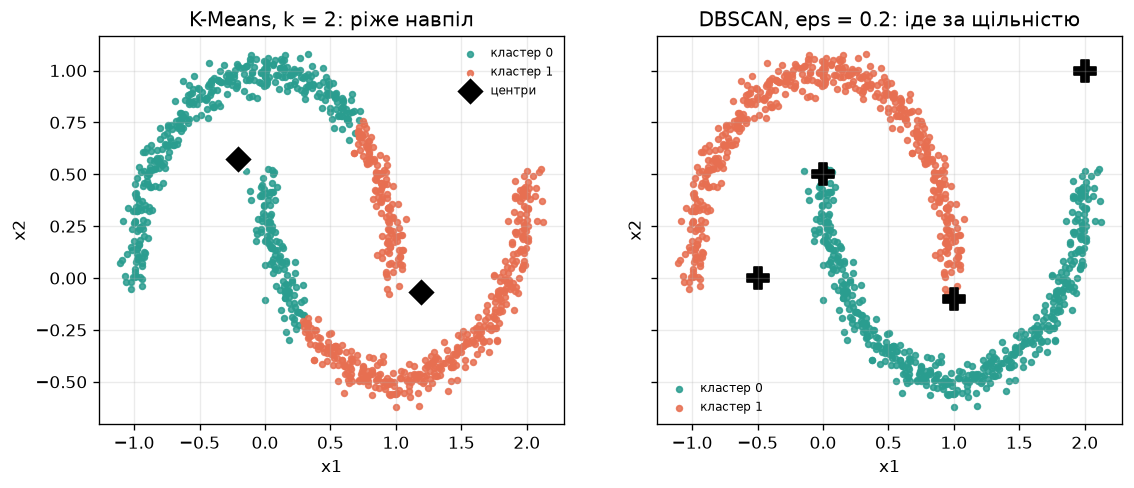

In [36]:
show("../PythonAI_Author_Lesson33_Lesson34/results/moons_compare.png")

**Що побачите.**
1. На двох півмісяцях `eps = 0.05` дає 7 кластерів і 77 точок шуму, `eps = 0.2` — рівно 2 кластери без шуму.
2. Збіг зі справжніми півмісяцями: K-Means 0.239 (ріже навпіл прямою), DBSCAN 1.000.
3. У DBSCAN немає `predict()`. Нові точки віддають kNN, навченому на ядрових точках: `[1 0 1 0]`, а з обмеженням відстані eps — `[-1 0 1 -1]`.

Рисунок — `results/moons_compare.png`.

**Перевір себе:**
12. Чому K-Means не може розділити півмісяці навіть за правильного `k = 2`?

<a id="step-14"></a>
## Крок 14 · 0:48–1:03 · K-Means і DBSCAN в одному вікні (завдання 7.2.4)

У презентації 34: «Приклад · дві панелі side-by-side», «ITSTEP Практичне 7.2 · завдання 3–4».

In [37]:
run("PythonAI_Author_Lesson33_Lesson34/Lesson34_04_comparison.py")

1) Ті самі 500 точок, два алгоритми
                            K-Means    DBSCAN
   кластерів                      4         4
   точок у шумі                   0        16
   збіг із хмарами, ARI       1.000     0.956
   silhouette                 0.791     0.799  (DBSCAN — без шуму)

2) Хто з ким разом: рядки — K-Means, стовпці — DBSCAN
cluster_dbscan  -1    0    1    2    3
cluster_kmeans                        
0                4    0    0    0  121
1                1  124    0    0    0
2                6    0    0  119    0
3                5    0  120    0    0

Рисунок: results\clustering_comparison.png
На круглих хмарах однакової щільності обидва бачать ті самі 4 групи. DBSCAN додатково
позначає крайніх клієнтів як шум — K-Means таких не має: він віддає кожну точку якомусь центру.



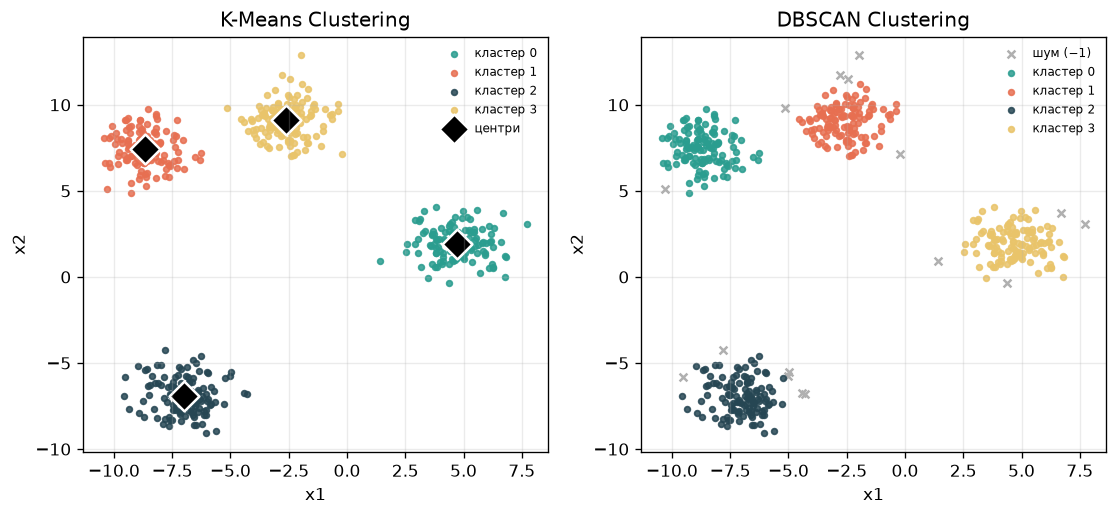

In [38]:
show("../PythonAI_Author_Lesson33_Lesson34/results/clustering_comparison.png")

**Що побачите.**

| | K-Means | DBSCAN |
|---|---|---|
| кластерів | 4 | 4 |
| точок у шумі | 0 | 16 |
| збіг із хмарами, ARI | 1.000 | 0.956 |
| silhouette | 0.791 | 0.799 (без шуму) |

Таблиця «хто з ким разом» показує: кожен кластер K-Means — це один кластер DBSCAN плюс кілька точок шуму. Рисунок `results/clustering_comparison.png` з заголовками `K-Means Clustering` і `DBSCAN Clustering`.

**Напишіть самі.** Файл `PythonAI_Author_Lesson33_Lesson34/my_dbscan.py` (готовий лежить у папці пари):

4 16


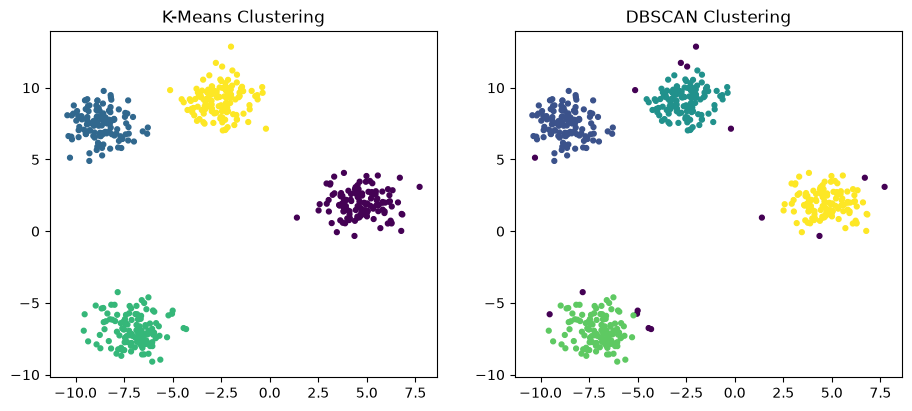

In [39]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=500, centers=4, cluster_std=1.0, random_state=42)
df = pd.DataFrame(X, columns=["x1", "x2"])
df["cluster_kmeans"] = KMeans(n_clusters=4, random_state=42).fit_predict(X)
df["cluster_dbscan"] = DBSCAN(eps=0.8, min_samples=5).fit_predict(X)

noise = int((df["cluster_dbscan"] == -1).sum())
print(df["cluster_dbscan"].nunique() - 1, noise)                           # 4 16  (кластери без шуму, шум)
# Міні-завдання 9: допишіть кількість шумових точок у заголовок правої панелі

fig = plt.figure(figsize=(11, 4.5))
plt.subplot(1, 2, 1)
plt.scatter(df["x1"], df["x2"], c=df["cluster_kmeans"], s=12)
plt.title("K-Means Clustering")
plt.subplot(1, 2, 2)
plt.scatter(df["x1"], df["x2"], c=df["cluster_dbscan"], s=12)
plt.title("DBSCAN Clustering")
plt.show()

**Міні-завдання 9 · 2 хв.** У `my_dbscan.py` допишіть кількість шумових точок у заголовок правої панелі (аналог 4.1), наприклад `DBSCAN Clustering · шум 16`.

**Перевір себе:**
13. Кому віддати сегментацію на круглих хмарах однакової щільності, а кому — на півмісяцях?

<a id="step-15"></a>
## Крок 15 · 1:03–1:20 · Практика

[Lesson34_tasks.md](../PythonAI_Author_Lesson33_Lesson34/Lesson34_tasks.md), завдання 3: DBSCAN на справжніх даних wine — графік k-відстаней, підбір eps, порівняння з K-Means.

Якщо важко — [Lesson33_tasks.md](../PythonAI_Author_Lesson33_Lesson34/Lesson33_tasks.md), завдання 3: скільки кластерів в ірисах.

Перед тим як показати результат, перевірте:
- [ ] ознаки масштабовано перед K-Means і DBSCAN;
- [ ] справжні мітки не потрапили в `fit`;
- [ ] надруковано кількість кластерів і шуму;
- [ ] рисунок збережено у файл.

<a id="step-16"></a>
## Крок 16 · 1:20–1:30 · Перевір себе і підсумок

14. Що означає мітка −1?
15. Чим ядрова точка відрізняється від межової?
16. Як вибрати eps?

**Підсумок.**
1. Кластеризація ділить точки на групи без правильних відповідей. Номер кластера — не клас.
2. K-Means: `k` задаємо самі; два кроки в циклі; кілька стартів; знаходить круглі групи схожого розміру.
3. Кількість кластерів підказують «лікоть» і silhouette, але вирішує задача.
4. DBSCAN: густі області замість `k`; шум −1; eps вибирають за графіком k-відстаней і лише після масштабування.
5. На круглих хмарах обидва алгоритми згодні, на півмісяцях виграє DBSCAN.

На парі 32 ви стиснули таблицю до карти, на парах 33–34 знайшли на карті групи без жодної підказки.

**Домашнє:** [Lesson33_homework.md](../PythonAI_Author_Lesson33_Lesson34/Lesson33_homework.md), [Lesson34_homework.md](../PythonAI_Author_Lesson33_Lesson34/Lesson34_homework.md).

**Наступна пара** — content-based рекомендації книг.